# Northbridge University – Admissions Shortlisting Decision-Support Model
**MSc Management with Data Analytics · Programming and Data Modelling · Summative CW04 – Task 2 (Programming Solution)**

## 1. Import libraries, load the data and combine it

### 1.1 Libraries

In [ ]:
import os
import re
import sys
import warnings
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)

# XGBoost is pre-installed in Google Colab, but install it if it is missing.
try:
    from xgboost import XGBClassifier
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
RANDOM_STATE = 42          # fixed seed so every run gives identical results
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


### 1.2 Locate and load the two files

In [ ]:
# --- Locate the files ---
FILE_A, FILE_B = "recruiter_A.csv", "recruiter_B.xlsx"
SEARCH_DIRS = [".", "/content", "/content/recruiter_A.csv", "/content/recruiter_B.xlsx"]

def find_file(name):
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and (find_file(FILE_A) is None or find_file(FILE_B) is None):
    print("Please upload recruiter_A.csv and recruiter_B.xlsx")
    files.upload()

path_a, path_b = find_file(FILE_A), find_file(FILE_B)
if path_a is None or path_b is None:
    raise FileNotFoundError("Could not find recruiter_A.csv / recruiter_B.xlsx - upload them first.")

# --- Load ---
df_a = pd.read_csv(path_a, keep_default_na=False, na_values=[""])
df_b = pd.read_excel(path_b, keep_default_na=False, na_values=[""])   # first sheet

print(f"recruiter_A.csv  : {df_a.shape[0]:,} rows x {df_a.shape[1]} columns")
print(f"recruiter_B.xlsx : {df_b.shape[0]:,} rows x {df_b.shape[1]} columns")
display(df_a.head(3))
display(df_b.head(3))

recruiter_A.csv  : 4,000 rows x 12 columns
recruiter_B.xlsx : 4,000 rows x 12 columns


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,None,1
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,None,1
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,None,1


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,B00001,61.3,76.1,3.80,State,Arts,95.6,0,Female,Other,None,0
1,B00002,56.6,60.9,2.81,State,Humanities,80.9,0,Female,Other,None,1
2,B00003,72.4,73.5,3.56,Independent,STEM,70.5,1,Male,White,None,1


### 1.3 Combine both datasets on the ID column (function)
`combine_datasets_on_id()` does the following:
1. Compares the column names of both files and reports which are shared. **Both files share the same 12 columns** (there is no `employee_id` / `attrition` column in this dataset, so there is no duplicate column to drop - each shared column appears once in the result).
2. Stacks the rows of both files (every applicant belongs to exactly one recruiter, so this is a row-wise combination).
3. Checks that `student_id` is unique and removes any repeated IDs.
4. Derives a `recruiter` column from the ID prefix (`A…` → Recruiter A, `B…` → Recruiter B), as described in the data dictionary.
5. Sets `student_id` as the index.

In [ ]:
def combine_datasets_on_id(df_1, df_2, id_col="student_id"):
    """Combine two recruiter datasets into one DataFrame indexed on `id_col`."""
    # 1) Compare schemas
    shared = [c for c in df_1.columns if c in df_2.columns]
    only_1 = [c for c in df_1.columns if c not in df_2.columns]
    only_2 = [c for c in df_2.columns if c not in df_1.columns]
    print(f"Shared columns: {len(shared)} | only in file 1: {only_1} | only in file 2: {only_2}")

    # 2) Stack the rows (columns are aligned by name, so each shared column appears once)
    combined = pd.concat([df_1, df_2], axis=0, ignore_index=True, sort=False)

    # 3) Validate the ID column
    n_dup = combined[id_col].duplicated().sum()
    print(f"Duplicate IDs found: {n_dup}")
    if n_dup:
        combined = combined.drop_duplicates(subset=id_col, keep="first")

    # 4) Recruiter from the ID prefix (letters before the digits)
    prefix = combined[id_col].astype(str).str.extract(r"^([A-Za-z]+)")[0].str.upper()
    combined["recruiter"] = prefix.map({"A": "Recruiter A", "B": "Recruiter B"})

    # 5) Index on the ID
    return combined.set_index(id_col)

df_raw = combine_datasets_on_id(df_a, df_b, id_col="student_id")
print("\nCombined shape:", df_raw.shape)
print("Index name    :", df_raw.index.name, "| index unique:", df_raw.index.is_unique)
display(df_raw.head())

Shared columns: 12 | only in file 1: [] | only in file 2: []
Duplicate IDs found: 0

Combined shape: (8000, 12)
Index name    : student_id | index unique: True


,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
student_id,,,,,,,,,,,,
A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,None,1,Recruiter A
A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,None,1,Recruiter A
A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,None,1,Recruiter A
A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,None,1,Recruiter A
A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,None,1,Recruiter A


## 2. Dataset exploration

### Step 1 - Size and first/last rows

In [ ]:
print("Shape (rows, columns):", df_raw.shape)
print("\nRecords per recruiter:")
print(df_raw["recruiter"].value_counts())
print("\nFirst 5 rows:")
display(df_raw.head())
print("Last 5 rows:")
display(df_raw.tail())

Shape (rows, columns): (8000, 12)

Records per recruiter:
recruiter
Recruiter A    4000
Recruiter B    4000
Name: count, dtype: int64

First 5 rows:


,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
student_id,,,,,,,,,,,,
A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,None,1,Recruiter A
A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,None,1,Recruiter A
A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,None,1,Recruiter A
A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,None,1,Recruiter A
A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,None,1,Recruiter A


Last 5 rows:


,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
student_id,,,,,,,,,,,,
B03996,62.4,59.0,2.54,State,Humanities,63.0,0,Male,Black,None,1,Recruiter B
B03997,86.2,81.6,4.22,State,Social Sciences,55.4,0,Male,White,None,1,Recruiter B
B03998,76.2,72.8,3.07,State,STEM,91.9,1,Female,Mixed,Learning,1,Recruiter B
B03999,67.3,72.6,3.63,Independent,Social Sciences,44.6,0,Male,White,None,1,Recruiter B
B04000,79.5,47.7,3.02,State,Arts,77.5,0,Male,Asian,None,1,Recruiter B


### Step 2 - Structure: column names, data types, non-null counts

In [ ]:
df_raw.info()
print("\nExpected types per the data dictionary: scores/distance = float, first_generation_student & admission_outcome = binary int, others = string.")

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, A00001 to B04000
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   prior_attainment_score    8000 non-null   float64
 1   admissions_test_score     8000 non-null   float64
 2   personal_statement_score  8000 non-null   float64
 3   school_type               7999 non-null   object 
 4   intended_subject_area     7999 non-null   object 
 5   distance_from_campus_km   7999 non-null   float64
 6   first_generation_student  8000 non-null   int64  
 7   gender                    8000 non-null   object 
 8   ethnicity                 8000 non-null   object 
 9   disability_status         7999 non-null   object 
 10  admission_outcome         8000 non-null   int64  
 11  recruiter                 8000 non-null   object 
dtypes: float64(4), int64(2), object(6)
memory usage: 1.0+ MB

Expected types per the data dictionary: scores/distance = 

### Step 3 - Summary statistics (numeric and categorical)

In [ ]:
print("Numeric columns:")
display(df_raw.describe().T.round(2))
print("Categorical columns - every distinct value and its count:")
for col in ["school_type", "intended_subject_area", "gender", "ethnicity", "disability_status", "recruiter"]:
    print(f"\n{col}:")
    print(df_raw[col].value_counts(dropna=False).to_string())

Numeric columns:


,count,mean,std,min,25%,50%,75%,max
prior_attainment_score,8000.0,70.01,9.90,32.00,63.40,70.00,76.70,105.70
admissions_test_score,8000.0,65.16,11.98,12.50,57.00,65.40,73.40,104.70
personal_statement_score,8000.0,3.21,0.81,-0.34,2.65,3.21,3.76,6.45
distance_from_campus_km,7999.0,89.53,52.82,2.40,51.00,79.50,117.20,519.10
first_generation_student,8000.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00
admission_outcome,8000.0,0.61,0.49,0.00,0.00,1.00,1.00,1.00


Categorical columns - every distinct value and its count:

school_type:
school_type
State            5205
Independent      1957
International     834
S                   2
I                   1
NaN                 1

intended_subject_area:
intended_subject_area
Social Sciences    2019
STEM               1997
Arts               1992
Humanities         1989
Soc                   1
A                     1
NaN                   1

gender:
gender
Female    4026
Male      3806
Other      164
M            2
F            2

ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563

disability_status:
disability_status
None        6209
Learning     807
Mental       492
Physical     491
NaN            1

recruiter:
recruiter
Recruiter A    4000
Recruiter B    4000


### Step 4 - Data-quality audit
Checks: missing values, duplicate records, ID format, labels that are **not** in the accepted list of the data dictionary, and numeric values outside their documented range.

In [ ]:
# 4a) Missing values
miss = df_raw.isna().sum()
print("Missing values per column (only columns with gaps):")
print(miss[miss > 0].to_string() if (miss > 0).any() else "none")

# 4b) Duplicates
print("\nDuplicate IDs      :", df_raw.index.duplicated().sum())
print("Fully duplicated rows (ignoring ID):", df_raw.duplicated().sum())

# 4c) ID format: one letter + 5 digits
bad_id = ~df_raw.index.to_series().str.match(r"^[AB]\d{5}$")
print("IDs not matching pattern [A/B + 5 digits]:", bad_id.sum())

# 4d) Labels outside the accepted values of the data dictionary
accepted = {
    "school_type": ["State", "Independent", "International"],
    "intended_subject_area": ["STEM", "Humanities", "Social Sciences", "Arts"],
    "gender": ["Male", "Female", "Other"],
    "ethnicity": ["White", "Black", "Asian", "Mixed", "Other"],
    "disability_status": ["None", "Physical", "Learning", "Mental Health"],
}
print("\nUnexpected category labels:")
for col, ok in accepted.items():
    bad = df_raw[col].dropna()[~df_raw[col].dropna().isin(ok)].value_counts()
    print(f"  {col:24s}: {bad.to_dict() if len(bad) else 'none'}")

# 4e) Numeric range violations
print("\nOut-of-range numeric values:")
print("  prior_attainment_score  > 100 or < 0 :", ((df_raw.prior_attainment_score > 100) | (df_raw.prior_attainment_score < 0)).sum())
print("  admissions_test_score   > 100 or < 0 :", ((df_raw.admissions_test_score > 100) | (df_raw.admissions_test_score < 0)).sum())
print("  personal_statement_score < 1 or > 5  :", ((df_raw.personal_statement_score < 1) | (df_raw.personal_statement_score > 5)).sum(), "(brief says 'typically 1-5')")
print("  distance_from_campus_km <= 0         :", (df_raw.distance_from_campus_km <= 0).sum())

Missing values per column (only columns with gaps):
school_type                1
intended_subject_area      1
distance_from_campus_km    1
disability_status          1

Duplicate IDs      : 0
Fully duplicated rows (ignoring ID): 0
IDs not matching pattern [A/B + 5 digits]: 0

Unexpected category labels:
  school_type             : {'S': 2, 'I': 1}
  intended_subject_area   : {'Soc': 1, 'A': 1}
  gender                  : {'M': 2, 'F': 2}
  ethnicity               : none
  disability_status       : {'Mental': 492}

Out-of-range numeric values:
  prior_attainment_score  > 100 or < 0 : 4
  admissions_test_score   > 100 or < 0 : 10
  personal_statement_score < 1 or > 5  : 133 (brief says 'typically 1-5')
  distance_from_campus_km <= 0         : 0


### Outlier plot 1 - the three score variables (boxplots)

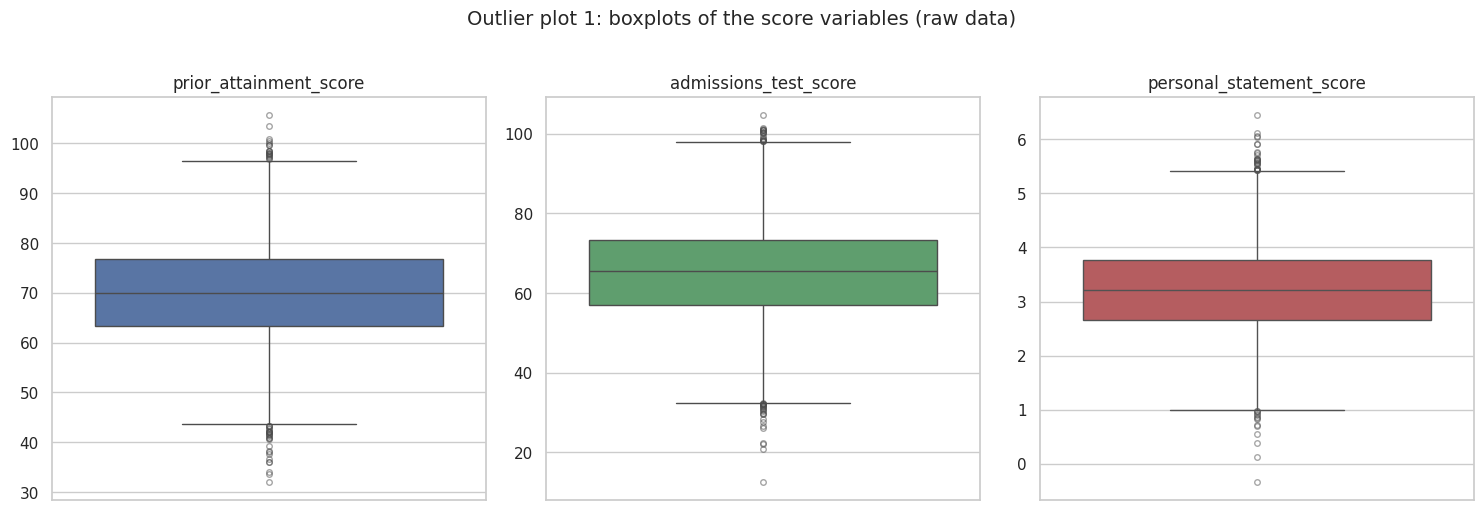

In [ ]:
score_cols = ["prior_attainment_score", "admissions_test_score", "personal_statement_score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, colour in zip(axes, score_cols, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.boxplot(y=df_raw[col], ax=ax, color=colour, flierprops=dict(marker="o", markersize=4, alpha=0.5))
    ax.set_title(f"{col}")
    ax.set_ylabel("")
fig.suptitle("Outlier plot 1: boxplots of the score variables (raw data)", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

### Outlier plot 2 - distance from campus (boxplot with IQR fence) and IQR outlier counts for all numeric variables

,lower_fence,upper_fence,n_outliers,pct_outliers
prior_attainment_score,43.45,96.65,46.0,0.57
admissions_test_score,32.40,98.00,42.0,0.52
personal_statement_score,0.99,5.42,41.0,0.51
distance_from_campus_km,-48.30,216.50,206.0,2.58


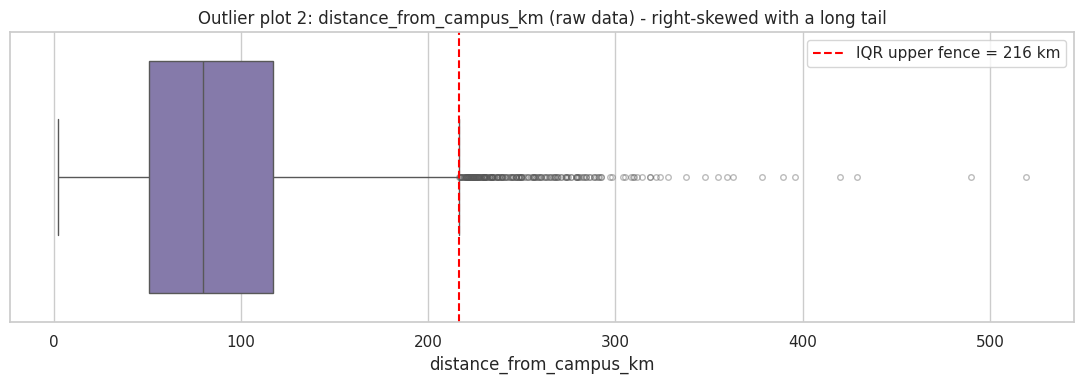

In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"lower_fence": lo, "upper_fence": hi,
                      "n_outliers": int(((s < lo) | (s > hi)).sum()),
                      "pct_outliers": round(((s < lo) | (s > hi)).mean() * 100, 2)})

num_cols = ["prior_attainment_score", "admissions_test_score", "personal_statement_score", "distance_from_campus_km"]
outlier_table = pd.DataFrame({c: iqr_outliers(df_raw[c].dropna()) for c in num_cols}).T
display(outlier_table.round(2))

fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(x=df_raw["distance_from_campus_km"], ax=ax, color="#8172B2", flierprops=dict(marker="o", markersize=4, alpha=0.4))
ax.axvline(outlier_table.loc["distance_from_campus_km", "upper_fence"], color="red", ls="--",
           label=f"IQR upper fence = {outlier_table.loc['distance_from_campus_km','upper_fence']:.0f} km")
ax.set_title("Outlier plot 2: distance_from_campus_km (raw data) - right-skewed with a long tail")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Data cleaning
Each step is printed so that it can be audited. Cleaning is done on a **copy** (`df`), leaving `df_raw` untouched.

| # | Issue | Treatment | Reason |
|---|---|---|---|
| 1 | Stray whitespace in text | `str.strip()` | Prevents "State " ≠ "State" |
| 2 | Abbreviated labels (`S`, `Soc`, `A`, `M`, `F`) | Map to the full label from the data dictionary | Unambiguous in context |
| 3 | `I` in `school_type` | Treated as **missing** | Could mean *Independent* **or** *International* - guessing would inject error |
| 4 | `Mental` | Rename to `Mental Health` | Matches the documented value |
| 5 | Missing categorical values | Mode (school type, subject); `Not stated` (disability) | Disability is never guessed |
| 6 | Missing `distance_from_campus_km` | Median | Robust to the long right tail |
| 7 | Scores outside valid scale | Cap: attainment/test to 0-100; personal statement to 1-5 | Values beyond the scale are impossible |
| 8 | Distance outliers | **Kept**, flagged in `distance_outlier_flag` | Genuine long-distance applicants |
| 9 | Duplicates | Dropped if present (none expected) | Avoids double counting |

In [ ]:
df = df_raw.copy()
log = {}   # keeps a count of changes per step, printed at the end

# 1) Whitespace
text_cols = ["school_type", "intended_subject_area", "gender", "ethnicity", "disability_status", "recruiter"]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()

# 2-4) Standardise labels
label_maps = {
    "school_type":           {"S": "State"},
    "intended_subject_area": {"Soc": "Social Sciences", "A": "Arts"},
    "gender":                {"M": "Male", "F": "Female"},
    "disability_status":     {"Mental": "Mental Health"},
}
for col, mapping in label_maps.items():
    n = df[col].isin(mapping.keys()).sum()
    df[col] = df[col].replace(mapping)
    log[f"relabelled {col}"] = int(n)

n_ambiguous = (df["school_type"] == "I").sum()          # ambiguous -> missing
df.loc[df["school_type"] == "I", "school_type"] = pd.NA
log["school_type 'I' set to missing (ambiguous)"] = int(n_ambiguous)

# 5-6) Missing values
log["missing before imputation"] = int(df.isna().sum().sum())
for col in ["school_type", "intended_subject_area"]:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f"{col}: missing filled with mode = '{mode_val}'")
df["disability_status"] = df["disability_status"].fillna("Not stated")
median_dist = df["distance_from_campus_km"].median()
df["distance_from_campus_km"] = df["distance_from_campus_km"].fillna(median_dist)
print(f"distance_from_campus_km: missing filled with median = {median_dist:.1f} km")
log["missing after imputation"] = int(df.isna().sum().sum())

# 7) Cap impossible score values
caps = {"prior_attainment_score": (0, 100), "admissions_test_score": (0, 100), "personal_statement_score": (1, 5)}
for col, (lo, hi) in caps.items():
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    df[col] = df[col].clip(lo, hi)
    log[f"capped {col} to [{lo},{hi}]"] = int(n)

# 8) Flag (do not remove) genuine distance outliers
q1, q3 = df["distance_from_campus_km"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
df["distance_outlier_flag"] = (df["distance_from_campus_km"] > fence).astype(int)
log["distance outliers flagged (kept)"] = int(df["distance_outlier_flag"].sum())

# 9) Duplicates
n_before = len(df)
df = df[~df.index.duplicated(keep="first")].drop_duplicates()
log["duplicate rows removed"] = n_before - len(df)

# Convert text columns back to ordinary categories for analysis
for c in text_cols:
    df[c] = df[c].astype(str)

print("\n=== Cleaning log ===")
for k, v in log.items():
    print(f"{k:55s}: {v}")
print("\nFinal shape:", df.shape)

school_type: missing filled with mode = 'State'
intended_subject_area: missing filled with mode = 'Social Sciences'
distance_from_campus_km: missing filled with median = 79.5 km

=== Cleaning log ===
relabelled school_type                                 : 2
relabelled intended_subject_area                       : 2
relabelled gender                                      : 4
relabelled disability_status                           : 492
school_type 'I' set to missing (ambiguous)             : 1
missing before imputation                              : 5
missing after imputation                               : 0
capped prior_attainment_score to [0,100]               : 4
capped admissions_test_score to [0,100]                : 10
capped personal_statement_score to [1,5]               : 133
distance outliers flagged (kept)                       : 206
duplicate rows removed                                 : 0

Final shape: (8000, 13)


**Validation after cleaning** - every check below must pass (assertions will stop the notebook otherwise).

In [ ]:
assert df.index.is_unique, "IDs not unique"
assert df.isna().sum().sum() == 0, "missing values remain"
for col, ok in accepted.items():
    allowed = ok + (["Not stated"] if col == "disability_status" else [])
    assert df[col].isin(allowed).all(), f"unexpected labels in {col}"
assert df[["prior_attainment_score", "admissions_test_score"]].apply(lambda s: s.between(0, 100).all()).all()
assert df["personal_statement_score"].between(1, 5).all()
assert set(df["admission_outcome"].unique()) <= {0, 1}
print("All validation checks passed.")
display(df.describe().T.round(2))

All validation checks passed.


,count,mean,std,min,25%,50%,75%,max
prior_attainment_score,8000.0,70.01,9.90,32.0,63.40,70.00,76.70,100.0
admissions_test_score,8000.0,65.16,11.98,12.5,57.00,65.40,73.40,100.0
personal_statement_score,8000.0,3.21,0.79,1.0,2.65,3.21,3.76,5.0
distance_from_campus_km,8000.0,89.53,52.81,2.4,51.00,79.50,117.20,519.1
first_generation_student,8000.0,0.35,0.48,0.0,0.00,0.00,1.00,1.0
admission_outcome,8000.0,0.61,0.49,0.0,0.00,1.00,1.00,1.0
distance_outlier_flag,8000.0,0.03,0.16,0.0,0.00,0.00,0.00,1.0


## 4. Descriptive analysis (Exploratory Data Analysis)
### 4.1 Number of records and overall offer rate

Number of records                  : 8,000
Applicants offered a place         : 4,850
Percentage of students offered a place: 60.62%
Percentage not offered             : 39.38%


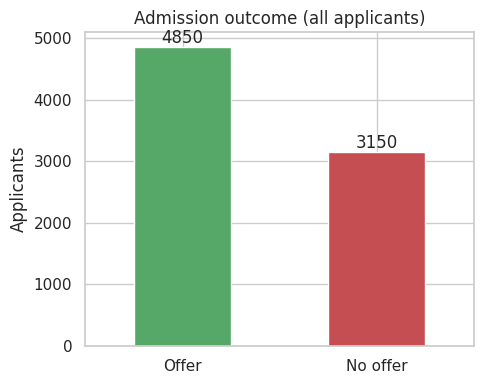

In [ ]:
n_records = len(df)
n_offers = int(df["admission_outcome"].sum())
offer_pct = n_offers / n_records * 100
print(f"Number of records                  : {n_records:,}")
print(f"Applicants offered a place         : {n_offers:,}")
print(f"Percentage of students offered a place: {offer_pct:.2f}%")
print(f"Percentage not offered             : {100 - offer_pct:.2f}%")

fig, ax = plt.subplots(figsize=(5, 4))
df["admission_outcome"].map({1: "Offer", 0: "No offer"}).value_counts().plot.bar(ax=ax, color=["#55A868", "#C44E52"])
ax.bar_label(ax.containers[0]); ax.set_title("Admission outcome (all applicants)"); ax.set_xlabel(""); ax.set_ylabel("Applicants")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 4.2 Places offered by gender

,applications,offers,offer_rate_%
gender,,,
Female,4028,2453,60.90
Male,3808,2307,60.58
Other,164,90,54.88


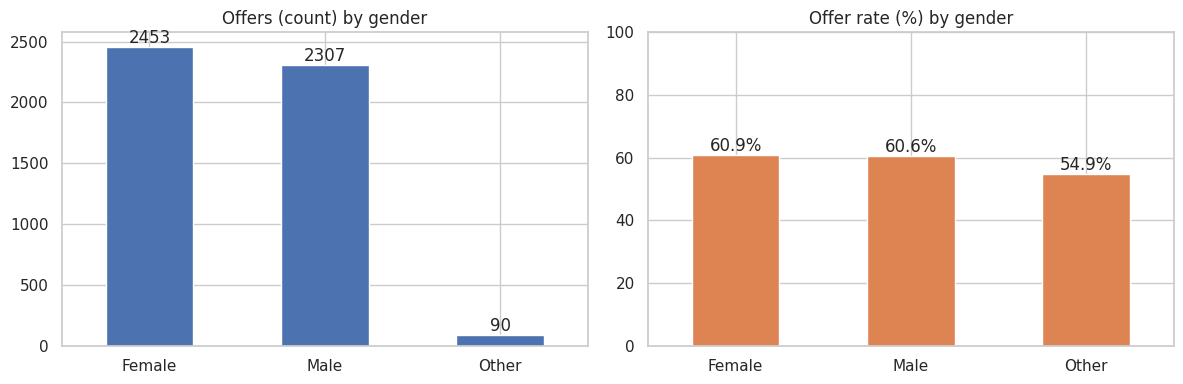

In [ ]:
gender_tbl = df.groupby("gender")["admission_outcome"].agg(applications="count", offers="sum")
gender_tbl["offer_rate_%"] = (gender_tbl["offers"] / gender_tbl["applications"] * 100).round(2)
display(gender_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
gender_tbl["offers"].plot.bar(ax=axes[0], color="#4C72B0"); axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Offers (count) by gender"); axes[0].set_xlabel(""); plt.setp(axes[0].get_xticklabels(), rotation=0)
gender_tbl["offer_rate_%"].plot.bar(ax=axes[1], color="#DD8452"); axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%")
axes[1].set_title("Offer rate (%) by gender"); axes[1].set_xlabel(""); axes[1].set_ylim(0, 100); plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

### 4.3 Number of applications and offer rate by recruiter

,applications,offers,offer_rate_%
recruiter,,,
Recruiter A,4000,2395,59.88
Recruiter B,4000,2455,61.38


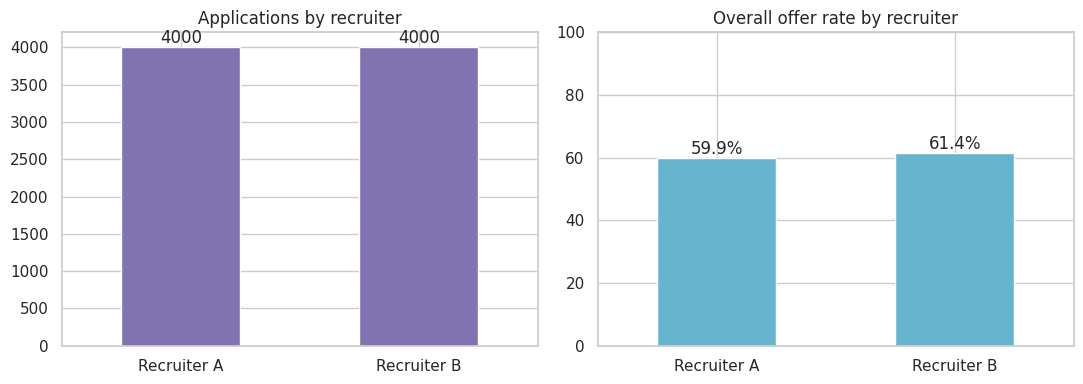

In [ ]:
rec_tbl = df.groupby("recruiter")["admission_outcome"].agg(applications="count", offers="sum")
rec_tbl["offer_rate_%"] = (rec_tbl["offers"] / rec_tbl["applications"] * 100).round(2)
display(rec_tbl)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rec_tbl["applications"].plot.bar(ax=axes[0], color="#8172B2"); axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Applications by recruiter"); axes[0].set_xlabel(""); plt.setp(axes[0].get_xticklabels(), rotation=0)
rec_tbl["offer_rate_%"].plot.bar(ax=axes[1], color="#64B5CD"); axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%")
axes[1].set_title("Overall offer rate by recruiter"); axes[1].set_xlabel(""); axes[1].set_ylim(0, 100); plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

### 4.4 Mean and median of the key numeric variables

In [ ]:
key_cols = ["prior_attainment_score", "admissions_test_score", "distance_from_campus_km"]
central = df[key_cols].agg(["mean", "median"]).T.round(2)
central["skew"] = df[key_cols].skew().round(2)
display(central)
print("Mean > median together with positive skew indicates a right-skewed variable (clearly the case for distance).")

,mean,median,skew
prior_attainment_score,70.01,70.0,-0.04
admissions_test_score,65.16,65.4,-0.05
distance_from_campus_km,89.53,79.5,1.28


Mean > median together with positive skew indicates a right-skewed variable (clearly the case for distance).


### 4.5 Distributions of the key numeric variables

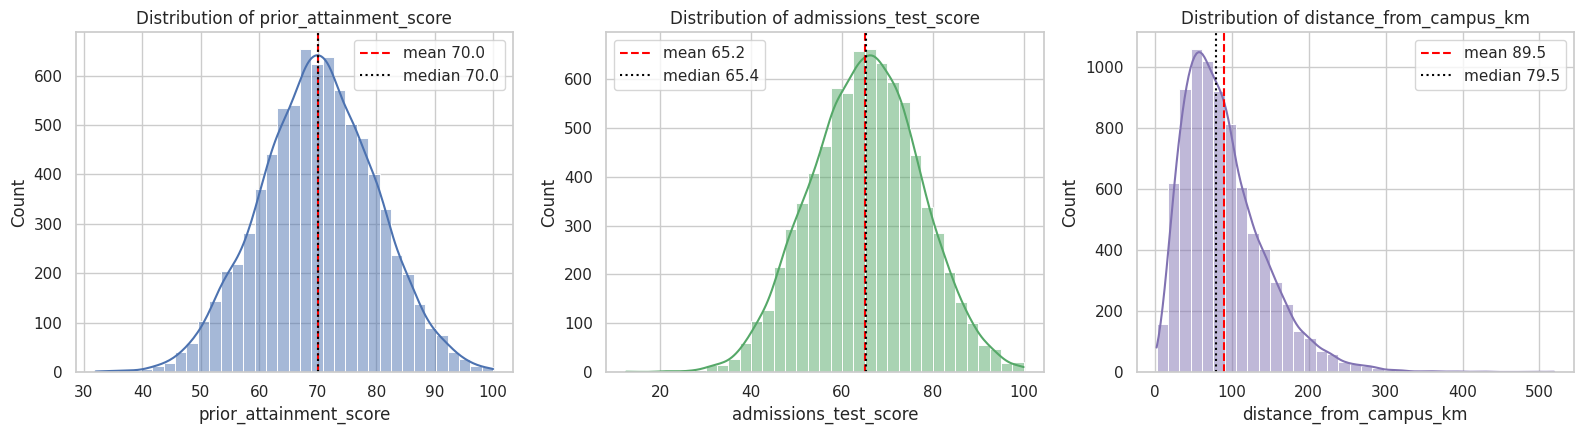

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, colour in zip(axes, key_cols, ["#4C72B0", "#55A868", "#8172B2"]):
    sns.histplot(df[col], kde=True, bins=35, ax=ax, color=colour)
    ax.axvline(df[col].mean(), color="red", ls="--", label=f"mean {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="black", ls=":", label=f"median {df[col].median():.1f}")
    ax.set_title(f"Distribution of {col}"); ax.legend()
plt.tight_layout(); plt.show()

### 4.6 Relationship between prior attainment and admissions test score

Pearson correlation (prior attainment vs admissions test): r = 0.015


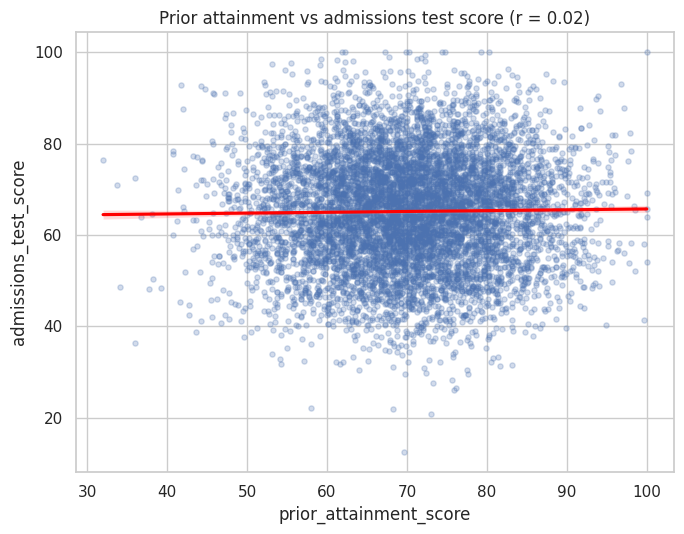

In [ ]:
r = df["prior_attainment_score"].corr(df["admissions_test_score"])
print(f"Pearson correlation (prior attainment vs admissions test): r = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.regplot(data=df, x="prior_attainment_score", y="admissions_test_score",
            scatter_kws=dict(alpha=0.25, s=14), line_kws=dict(color="red"), ax=ax)
ax.set_title(f"Prior attainment vs admissions test score (r = {r:.2f})")
plt.tight_layout(); plt.show()

### 4.7 Disability, age, gender proportion, offers by ethnicity, subject area by gender

Disability distribution:


,count,%
disability_status,,
None,6209,77.61
Learning,807,10.09
Mental Health,492,6.15
Physical,491,6.14
Not stated,1,0.01


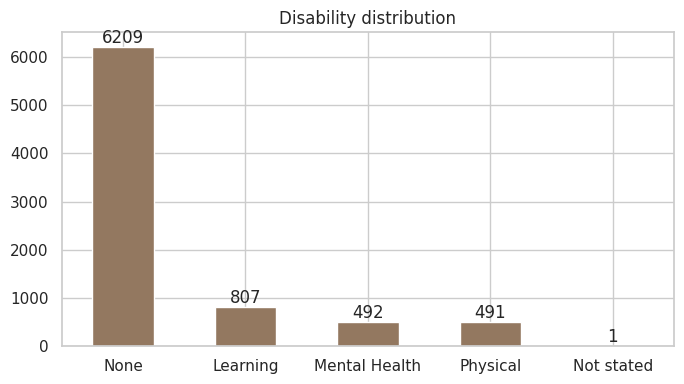

Age distribution: NOT AVAILABLE - neither source file contains an age column (the data dictionary does not list one), so this optional analysis cannot be performed.


In [ ]:
# --- Disability distribution ---
dis = df["disability_status"].value_counts()
print("Disability distribution:"); display(pd.DataFrame({"count": dis, "%": (dis / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(7, 4))
dis.plot.bar(ax=ax, color="#937860"); ax.bar_label(ax.containers[0])
ax.set_title("Disability distribution"); ax.set_xlabel(""); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# --- Age distribution ---
age_cols = [c for c in df.columns if "age" in c.lower().split("_")]
if age_cols:
    sns.histplot(df[age_cols[0]], kde=True); plt.title("Age distribution"); plt.show()
else:
    print("Age distribution: NOT AVAILABLE - neither source file contains an age column "
          "(the data dictionary does not list one), so this optional analysis cannot be performed.")

Gender proportion (%):
gender
Female    50.35
Male      47.60
Other      2.05


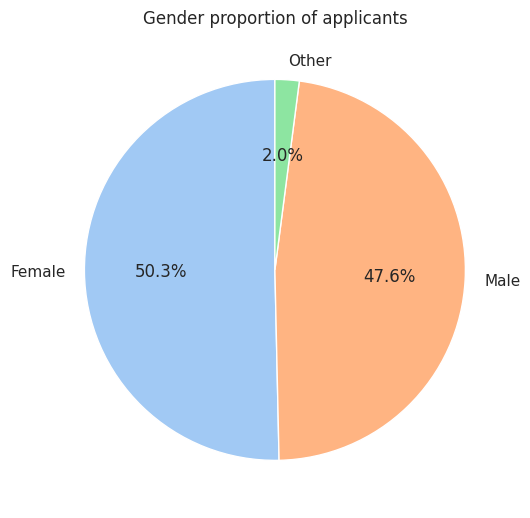

In [ ]:
# --- Gender proportion ---
gp = df["gender"].value_counts(normalize=True).mul(100).round(2)
print("Gender proportion (%):"); print(gp.to_string())
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(gp, labels=gp.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
ax.set_title("Gender proportion of applicants"); plt.tight_layout(); plt.show()

,applications,offers,offer_rate_%
ethnicity,,,
Asian,1597,974,60.99
Black,1593,993,62.34
Mixed,1614,985,61.03
Other,1633,974,59.64
White,1563,924,59.12


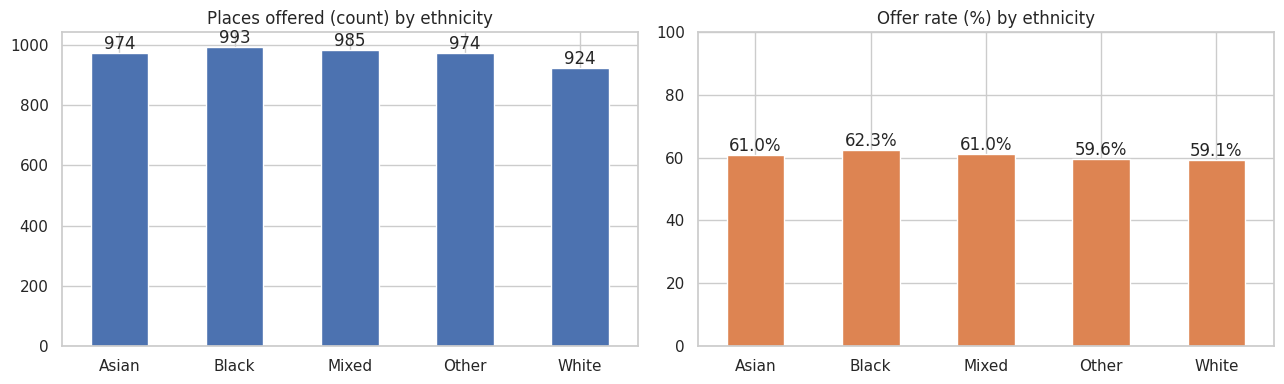

In [ ]:
# --- Places offered by ethnicity ---
eth = df.groupby("ethnicity")["admission_outcome"].agg(applications="count", offers="sum")
eth["offer_rate_%"] = (eth["offers"] / eth["applications"] * 100).round(2)
display(eth)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
eth["offers"].plot.bar(ax=axes[0], color="#4C72B0"); axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Places offered (count) by ethnicity"); axes[0].set_xlabel(""); plt.setp(axes[0].get_xticklabels(), rotation=0)
eth["offer_rate_%"].plot.bar(ax=axes[1], color="#DD8452"); axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%")
axes[1].set_title("Offer rate (%) by ethnicity"); axes[1].set_xlabel(""); axes[1].set_ylim(0, 100); plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

Counts:


gender,Female,Male,Other
intended_subject_area,,,
Arts,1004,947,42
Humanities,1011,938,40
STEM,981,975,41
Social Sciences,1032,948,41


Row % (share of each gender within a subject):


gender,Female,Male,Other
intended_subject_area,,,
Arts,50.4,47.5,2.1
Humanities,50.8,47.2,2.0
STEM,49.1,48.8,2.1
Social Sciences,51.1,46.9,2.0


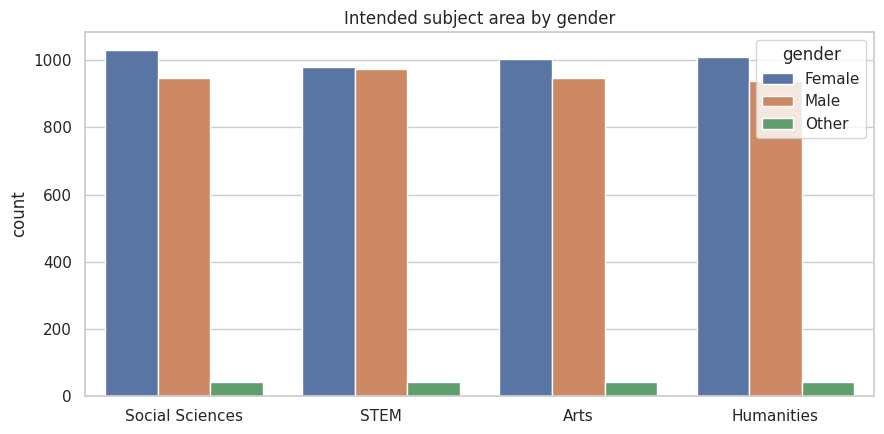

In [ ]:
# --- Distribution of intended subject area by gender ---
subj_gender = pd.crosstab(df["intended_subject_area"], df["gender"])
print("Counts:"); display(subj_gender)
print("Row % (share of each gender within a subject):"); display(pd.crosstab(df["intended_subject_area"], df["gender"], normalize="index").mul(100).round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="intended_subject_area", hue="gender", ax=ax, order=subj_gender.sum(axis=1).sort_values(ascending=False).index)
ax.set_title("Intended subject area by gender"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 5. Data preparation for modelling
### 5.1 Ethical feature selection

In [ ]:
ACADEMIC  = ["prior_attainment_score", "admissions_test_score", "personal_statement_score"]
COURSE    = ["intended_subject_area"]
PROXY     = ["school_type", "distance_from_campus_km"]
PROTECTED = ["gender", "ethnicity", "disability_status", "first_generation_student"]
TARGET    = "admission_outcome"

INCLUDE_PROXY_FEATURES = False     # <- set True to test the effect of the proxy variables (sensitivity analysis)

feature_cols = ACADEMIC + COURSE + (PROXY if INCLUDE_PROXY_FEATURES else [])
print("Model input features:", feature_cols)

# One-hot encode the categorical inputs (drop_first avoids redundant columns). This step uses no target
# information, so doing it before the split does not leak anything.
X = pd.get_dummies(df[feature_cols], drop_first=True).astype(float)
y = df[TARGET].astype(int)
print("Feature matrix shape:", X.shape)
display(X.head())

Model input features: ['prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'intended_subject_area']
Feature matrix shape: (8000, 6)


,prior_attainment_score,admissions_test_score,personal_statement_score,intended_subject_area_Humanities,intended_subject_area_STEM,intended_subject_area_Social Sciences
student_id,,,,,,
A00001,59.1,59.3,2.94,1.0,0.0,0.0
A00002,80.0,78.0,3.60,1.0,0.0,0.0
A00003,72.8,60.4,3.31,0.0,0.0,0.0
A00004,54.9,60.7,3.52,0.0,1.0,0.0
A00005,64.2,56.8,2.99,0.0,0.0,0.0


### 5.2 Train / validation / test split (70 / 15 / 15, stratified)
* **Training set** - fits the models.
* **Validation set** - used for early stopping (XGBoost) and to monitor over-fitting.
* **Test set** - touched **only once**, for the final evaluation.

`stratify=y` keeps the offer rate identical in all three sets.

In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.15 / 0.85,
                                                  stratify=y_train_val, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "records": [len(X_train), len(X_val), len(X_test)],
    "share_%": [round(len(a) / len(X) * 100, 1) for a in (X_train, X_val, X_test)],
    "offer_rate_%": [round(s.mean() * 100, 2) for s in (y_train, y_val, y_test)]},
    index=["train", "validation", "test"])
display(split_summary)

,records,share_%,offer_rate_%
train,5600,70.0,60.62
validation,1200,15.0,60.67
test,1200,15.0,60.58


## 6. Modelling
### Model 1 - Logistic Regression
* A linear model for the log-odds of an offer - **transparent**: each coefficient has a direct interpretation, which supports the explainability duty to rejected applicants.
* Features are standardised (`StandardScaler`, fitted on training data only) inside a `Pipeline`, so no information from validation/test data leaks into training.

Standardised coefficients (log-odds per 1 SD change):


,coefficient
intended_subject_area_STEM,-0.004
intended_subject_area_Social Sciences,0.018
intended_subject_area_Humanities,0.028
personal_statement_score,0.076
prior_attainment_score,0.192
admissions_test_score,0.226


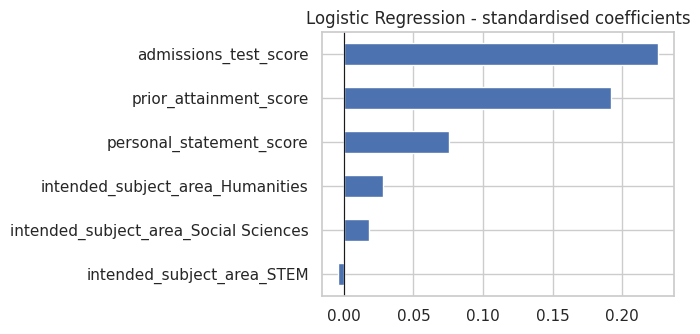

In [ ]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
lr_model.fit(X_train, y_train)

coef = pd.Series(lr_model.named_steps["clf"].coef_[0], index=X.columns).sort_values()
print("Standardised coefficients (log-odds per 1 SD change):")
display(coef.round(3).to_frame("coefficient"))
fig, ax = plt.subplots(figsize=(7, 3.5)); coef.plot.barh(ax=ax, color="#4C72B0"); ax.axvline(0, color="k", lw=0.8)
ax.set_title("Logistic Regression - standardised coefficients"); plt.tight_layout(); plt.show()

### Model 2 - XGBoost
* An ensemble of boosted decision trees that can model non-linear effects and interactions.
* **Regularised and early-stopped:** shallow trees (`max_depth=3`), small learning rate, row/column sub-sampling, and training stops when the **validation log-loss** stops improving (30 rounds patience) - this controls over-fitting on a dataset with a weak signal.

Best iteration (early stopping): 87 of max 1000 trees


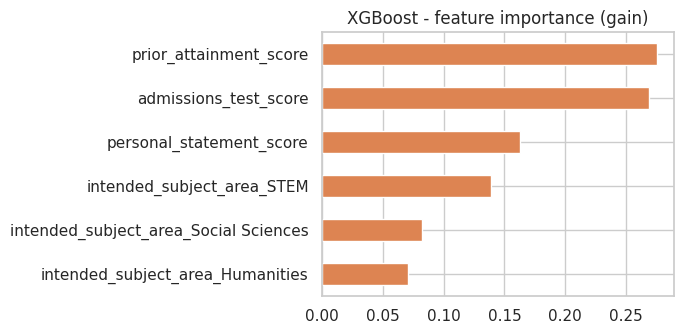

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=1000, learning_rate=0.03, max_depth=3,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0,
    eval_metric="logloss", early_stopping_rounds=30,
    random_state=RANDOM_STATE, n_jobs=-1
)
xgb_model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print("Best iteration (early stopping):", xgb_model.best_iteration, "of max 1000 trees")

imp = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5)); imp.plot.barh(ax=ax, color="#DD8452")
ax.set_title("XGBoost - feature importance (gain)"); plt.tight_layout(); plt.show()

## 7. Model evaluation (each model evaluated separately)
Reported for each model: **accuracy**, a **classification report** (precision / recall / F1), **log-loss** on train / validation / test, a **confusion matrix** and a **ROC-AUC curve**.

In [ ]:
# Baseline: always predict the training offer rate (no information about the applicant)
p_base = y_train.mean()
baseline_logloss = log_loss(y_test, np.full(len(y_test), p_base))
baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline (no-skill) test log-loss : {baseline_logloss:.4f}")
print(f"Baseline (always predict majority class) test accuracy: {baseline_accuracy:.4f}")

Baseline (no-skill) test log-loss : 0.6706
Baseline (always predict majority class) test accuracy: 0.6058


### 7.1 Model 1 - Logistic Regression

In [ ]:
# Predictions
lr_pred_test  = lr_model.predict(X_test)
lr_proba_test = lr_model.predict_proba(X_test)[:, 1]

# Accuracy
lr_acc_train = accuracy_score(y_train, lr_model.predict(X_train))
lr_acc_val   = accuracy_score(y_val,   lr_model.predict(X_val))
lr_acc_test  = accuracy_score(y_test,  lr_pred_test)
print("LOGISTIC REGRESSION")
print(f"Accuracy  - train: {lr_acc_train:.4f} | validation: {lr_acc_val:.4f} | test: {lr_acc_test:.4f}")

# Classification report (test set)
print("\nClassification report (test set):")
print(classification_report(y_test, lr_pred_test, target_names=["No offer (0)", "Offer (1)"], digits=3))

# Log-loss (its own loss function, train / validation / test)
lr_ll_train = log_loss(y_train, lr_model.predict_proba(X_train)[:, 1])
lr_ll_val   = log_loss(y_val,   lr_model.predict_proba(X_val)[:, 1])
lr_ll_test  = log_loss(y_test,  lr_proba_test)
print(f"Log-loss  - train: {lr_ll_train:.4f} | validation: {lr_ll_val:.4f} | test: {lr_ll_test:.4f}  (baseline {baseline_logloss:.4f})")

LOGISTIC REGRESSION
Accuracy  - train: 0.6100 | validation: 0.6008 | test: 0.6125

Classification report (test set):
              precision    recall  f1-score   support

No offer (0)      0.551     0.091     0.156       473
   Offer (1)      0.617     0.952     0.749       727

    accuracy                          0.613      1200
   macro avg      0.584     0.521     0.452      1200
weighted avg      0.591     0.613     0.515      1200

Log-loss  - train: 0.6592 | validation: 0.6613 | test: 0.6638  (baseline 0.6706)


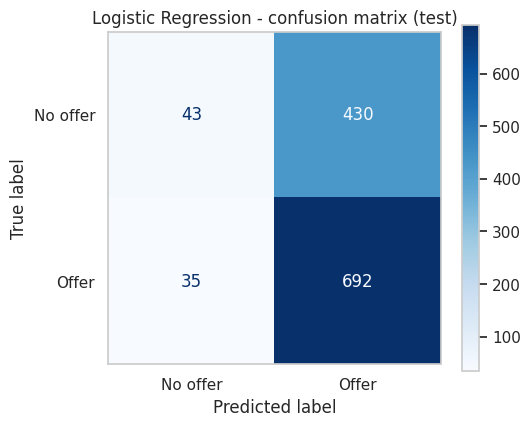

In [ ]:
# Confusion matrix - Logistic Regression (Blues colour map)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred_test, display_labels=["No offer", "Offer"], cmap="Blues", ax=ax, colorbar=True)
ax.set_title("Logistic Regression - confusion matrix (test)"); ax.grid(False)
plt.tight_layout(); plt.show()

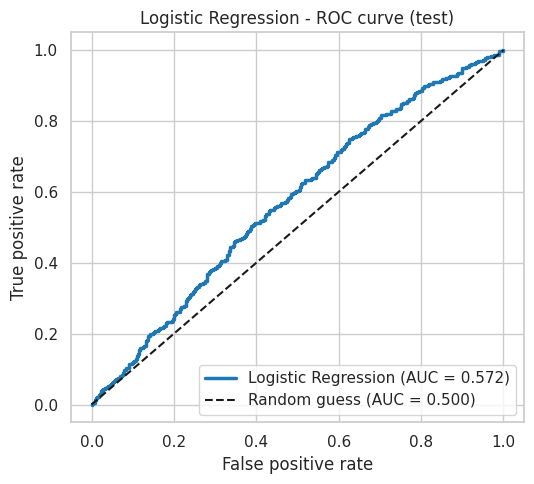

In [ ]:
# ROC-AUC curve - Logistic Regression
lr_auc = roc_auc_score(y_test, lr_proba_test)
fpr, tpr, _ = roc_curve(y_test, lr_proba_test)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#1f77b4", lw=2.5, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Logistic Regression - ROC curve (test)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 7.2 Model 2 - XGBoost

XGBOOST
Accuracy  - train: 0.6148 | validation: 0.6017 | test: 0.6083

Classification report (test set):
              precision    recall  f1-score   support

No offer (0)      0.543     0.040     0.075       473
   Offer (1)      0.610     0.978     0.752       727

    accuracy                          0.608      1200
   macro avg      0.577     0.509     0.413      1200
weighted avg      0.584     0.608     0.485      1200

Log-loss  - train: 0.6511 | validation: 0.6625 | test: 0.6628  (baseline 0.6706)


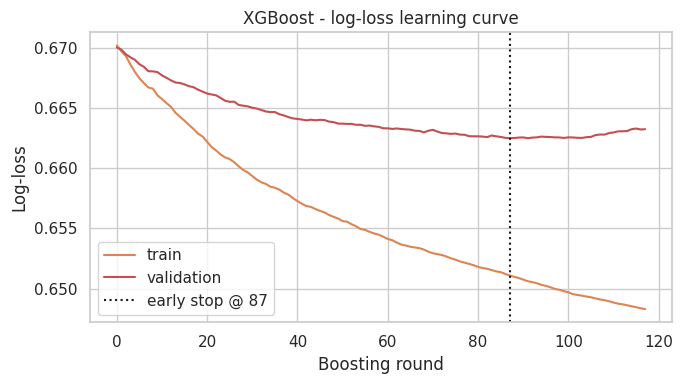

In [ ]:
# Predictions
xgb_pred_test  = xgb_model.predict(X_test)
xgb_proba_test = xgb_model.predict_proba(X_test)[:, 1]

# Accuracy
xgb_acc_train = accuracy_score(y_train, xgb_model.predict(X_train))
xgb_acc_val   = accuracy_score(y_val,   xgb_model.predict(X_val))
xgb_acc_test  = accuracy_score(y_test,  xgb_pred_test)
print("XGBOOST")
print(f"Accuracy  - train: {xgb_acc_train:.4f} | validation: {xgb_acc_val:.4f} | test: {xgb_acc_test:.4f}")

# Classification report (test set)
print("\nClassification report (test set):")
print(classification_report(y_test, xgb_pred_test, target_names=["No offer (0)", "Offer (1)"], digits=3))

# Log-loss (its own loss function, train / validation / test)
xgb_ll_train = log_loss(y_train, xgb_model.predict_proba(X_train)[:, 1])
xgb_ll_val   = log_loss(y_val,   xgb_model.predict_proba(X_val)[:, 1])
xgb_ll_test  = log_loss(y_test,  xgb_proba_test)
print(f"Log-loss  - train: {xgb_ll_train:.4f} | validation: {xgb_ll_val:.4f} | test: {xgb_ll_test:.4f}  (baseline {baseline_logloss:.4f})")

# Log-loss learning curve across boosting rounds
hist = xgb_model.evals_result()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["validation_0"]["logloss"], label="train", color="#DD8452")
ax.plot(hist["validation_1"]["logloss"], label="validation", color="#C44E52")
ax.axvline(xgb_model.best_iteration, color="k", ls=":", label=f"early stop @ {xgb_model.best_iteration}")
ax.set_xlabel("Boosting round"); ax.set_ylabel("Log-loss"); ax.set_title("XGBoost - log-loss learning curve"); ax.legend()
plt.tight_layout(); plt.show()

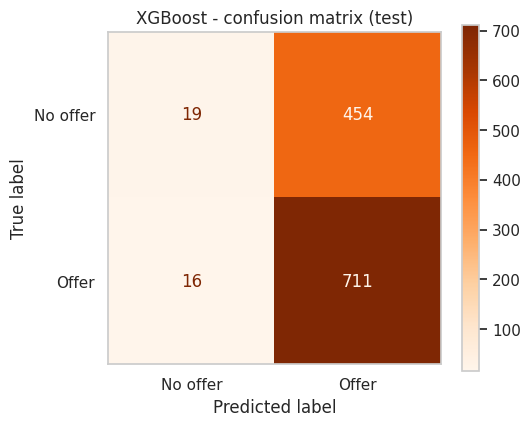

In [ ]:
# Confusion matrix - XGBoost (Oranges colour map)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, xgb_pred_test, display_labels=["No offer", "Offer"], cmap="Oranges", ax=ax, colorbar=True)
ax.set_title("XGBoost - confusion matrix (test)"); ax.grid(False)
plt.tight_layout(); plt.show()

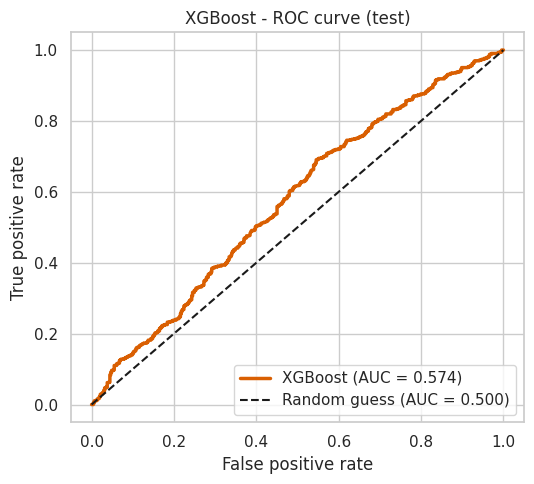

In [ ]:
# ROC-AUC curve - XGBoost
xgb_auc = roc_auc_score(y_test, xgb_proba_test)
fpr, tpr, _ = roc_curve(y_test, xgb_proba_test)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#d95f02", lw=2.5, label=f"XGBoost (AUC = {xgb_auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("XGBoost - ROC curve (test)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 7.3 Summary table of accuracy metrics and model selection

,Accuracy (test),Precision (offer),Recall (offer),F1 (offer),ROC-AUC (test),Log-loss (test),Log-loss (train),Train-test log-loss gap
Logistic Regression,0.612500,0.6168,0.9519,0.7485,0.5723,0.663800,0.6592,0.0046
XGBoost,0.608300,0.6103,0.9780,0.7516,0.5744,0.662800,0.6511,0.0117
Baseline (no skill),0.605833,NaN,NaN,NaN,0.5000,0.670576,NaN,NaN


Lowest test log-loss : XGBoost
Highest test ROC-AUC : XGBoost


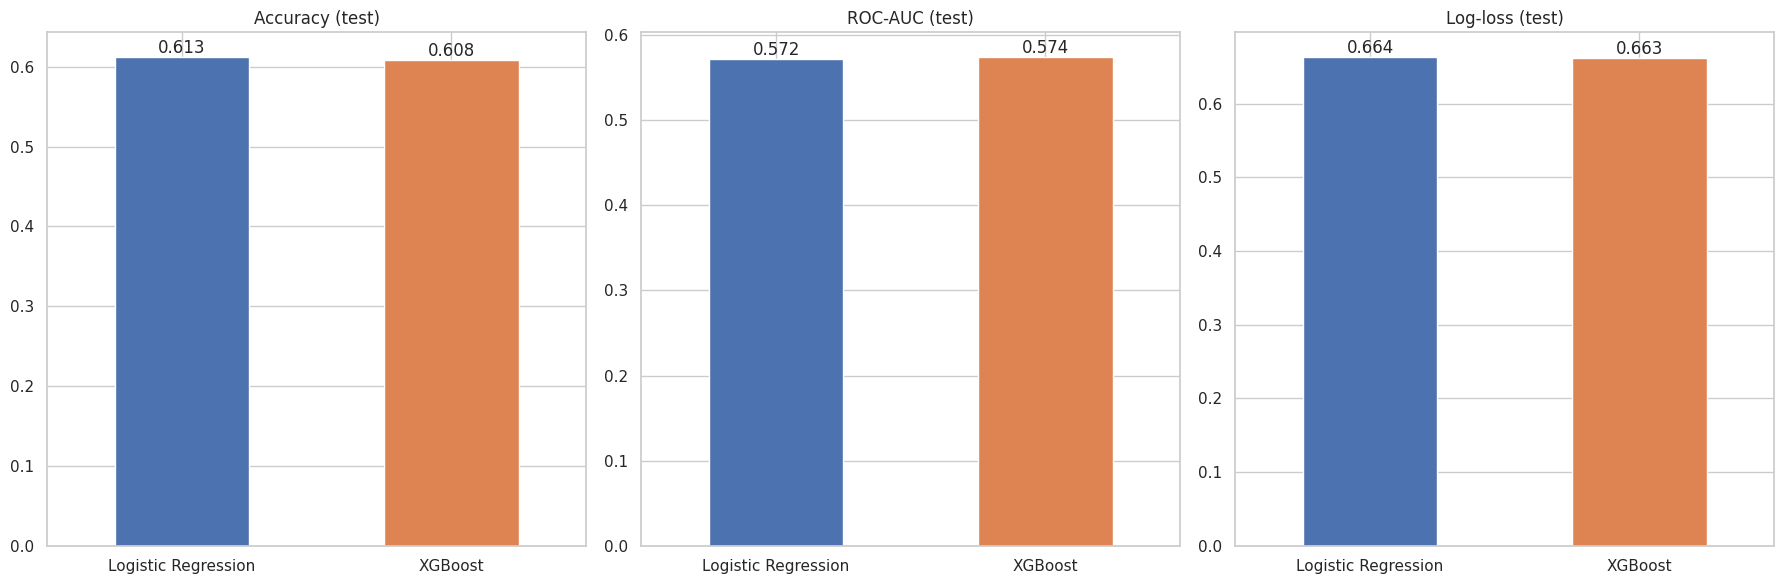

In [ ]:
summary = pd.DataFrame({
    "Accuracy (test)":  [lr_acc_test, xgb_acc_test],
    "Precision (offer)": [precision_score(y_test, lr_pred_test), precision_score(y_test, xgb_pred_test)],
    "Recall (offer)":    [recall_score(y_test, lr_pred_test), recall_score(y_test, xgb_pred_test)],
    "F1 (offer)":        [f1_score(y_test, lr_pred_test), f1_score(y_test, xgb_pred_test)],
    "ROC-AUC (test)":    [lr_auc, xgb_auc],
    "Log-loss (test)":   [lr_ll_test, xgb_ll_test],
    "Log-loss (train)":  [lr_ll_train, xgb_ll_train],
    "Train-test log-loss gap": [lr_ll_test - lr_ll_train, xgb_ll_test - xgb_ll_train],
}, index=["Logistic Regression", "XGBoost"]).round(4)
summary.loc["Baseline (no skill)"] = [baseline_accuracy, np.nan, np.nan, np.nan, 0.5, baseline_logloss, np.nan, np.nan]
display(summary)

# Model selection: lowest test log-loss (primary), highest AUC (secondary)
best_by_ll  = summary.loc[["Logistic Regression", "XGBoost"], "Log-loss (test)"].idxmin()
best_by_auc = summary.loc[["Logistic Regression", "XGBoost"], "ROC-AUC (test)"].idxmax()
print(f"Lowest test log-loss : {best_by_ll}")
print(f"Highest test ROC-AUC : {best_by_auc}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, metric in zip(axes, ["Accuracy (test)", "ROC-AUC (test)", "Log-loss (test)"]):
    vals = summary.loc[["Logistic Regression", "XGBoost"], metric]
    vals.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"]); ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(metric); ax.set_xlabel(""); plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()